# Market Risk and CCR Assignment
# Risk Management
# Author: Jaime Corzo Galdó

## 1. Delta-Gamma approximation of a European call

The value of a European call option under the Black-Scholes model is$$C(S,K,r,q,\sigma,T) = S e^{-qT}N(d_1) - K e^{-rT}N(d_2),$$where$$d_1 = \frac{\ln(S/K) + \left(r - q + \frac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}.$$Here, $S$ is the stock price, $K$ the strike, $r$ the risk-free rate, $q$ the dividend yield, $\sigma$ the volatility, and $T$ the time to maturity.For this exercise, only the stock price is shocked. The other Black-Scholes inputs are kept fixed. Therefore, the option value can be viewed locally as a function of $S$.A Taylor expansion of the option value around the initial stock price $S_0$ gives$$C(S_0 + \Delta S) \approx C(S_0) + \frac{\partial C}{\partial S}\Delta S + \frac{1}{2}\frac{\partial^2 C}{\partial S^2}(\Delta S)^2 + \cdots$$Using the usual notation for the Greeks,$$\Delta = \frac{\partial C}{\partial S}, \qquad \Gamma = \frac{\partial^2 C}{\partial S^2}.$$The first-order approximation therefore uses only Delta, while the second-order approximation also includes Gamma. Since this expansion is made around $S_0$, its accuracy is expected to decrease as the stock price moves further away from the initial value.

### (a) Black-Scholes price and full revaluation
The initial option value is first calculated using the original market parameters.For each stock-price shock $x$, the new stock price is$$S_x = S_0(1 + x).$$The option is then priced again with the Black-Scholes formula using $S_x$, while all other parameters remain unchanged.The corresponding change in option value is$$\Delta C_{\text{full}} = C(S_x) - C(S_0).$$This procedure is referred to as full revaluation, since the pricing model is evaluated again after applying each shock rather than using a sensitivity approximation.

In [4]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# Black-Scholes price of a European call
def bs_call(S, K, r, q, sigma, T):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    price = S * np.exp(-q * T) * norm.cdf(d1) \
            - K * np.exp(-r * T) * norm.cdf(d2)

    return price


# Initial parameters
S0 = 100
K = 100
r = 0.02
q = 0.00
sigma = 0.25
T = 0.5

shocks = np.array([-0.20, -0.10, -0.05, 0.05, 0.10, 0.20])


# Initial Black-Scholes price
C0 = bs_call(S0, K, r, q, sigma, T)

print(f"Initial call price: {C0:.4f}")

Initial call price: 7.5168


In [5]:
results = pd.DataFrame({"Shock": shocks})

# Shocked stock prices
results["Stock price"] = S0 * (1 + results["Shock"])

# Full Black-Scholes revaluation
results["Full revaluation price"] = results["Stock price"].apply(
    lambda S: bs_call(S, K, r, q, sigma, T)
)

# Exact change relative to the original option value
results["Full revaluation change"] = (
    results["Full revaluation price"] - C0
)

results

,Shock,Stock price,Full revaluation price,Full revaluation change
0,-0.20,80.0,0.870028,-6.646818
1,-0.10,90.0,3.095772,-4.421074
2,-0.05,95.0,5.014621,-2.502225
3,0.05,105.0,10.574251,3.057404
4,0.10,110.0,14.121816,6.604969
5,0.20,120.0,22.345599,14.828753


### (b) Delta and Delta-Gamma approximations
Instead of repricing the option after every stock-price shock, the change in value can be approximated using sensitivities calculated at the initial market parameters.For a stock-price change$$\Delta S = S_x - S_0,$$the Delta-only approximation is$$\Delta C_{\Delta} \approx \Delta\,\Delta S.$$This is a first-order approximation and treats the option value as locally linear in the stock price.The Delta-Gamma approximation also includes the curvature of the option value:$$\Delta C_{\Delta+\Gamma} \approx \Delta\,\Delta S + \frac{1}{2}\Gamma(\Delta S)^2.$$Gamma is particularly relevant for options because their relationship with the underlying stock price is nonlinear.For both approximations, Delta and Gamma are evaluated once at the initial parameters. Full revaluation, in contrast, evaluates the complete Black-Scholes pricing function at each shocked stock price. The full-revaluation change is therefore used as the benchmark against which the two approximations are compared.

In [6]:
def call_delta(S, K, r, q, sigma, T):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return np.exp(-q * T) * norm.cdf(d1)


def call_gamma(S, K, r, q, sigma, T):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

    return (
        np.exp(-q * T) * norm.pdf(d1)
        / (S * sigma * np.sqrt(T))
    )


# Greeks at the initial market parameters
delta0 = call_delta(S0, K, r, q, sigma, T)
gamma0 = call_gamma(S0, K, r, q, sigma, T)

print(f"Initial Delta: {delta0:.6f}")
print(f"Initial Gamma: {gamma0:.6f}")

Initial Delta: 0.557628
Initial Gamma: 0.022332


In [7]:
# Dollar change in the stock price
results["Delta S"] = results["Stock price"] - S0

# First-order approximation
results["Delta-only change"] = (
    delta0 * results["Delta S"]
)

# Second-order approximation
results["Delta-Gamma change"] = (
    delta0 * results["Delta S"]
    + 0.5 * gamma0 * results["Delta S"]**2
)

comparison = results[
    [
        "Shock",
        "Stock price",
        "Full revaluation change",
        "Delta-only change",
        "Delta-Gamma change"
    ]
].copy()

comparison

,Shock,Stock price,Full revaluation change,Delta-only change,Delta-Gamma change
0,-0.20,80.0,-6.646818,-11.152551,-6.686206
1,-0.10,90.0,-4.421074,-5.576275,-4.459689
2,-0.05,95.0,-2.502225,-2.788138,-2.508991
3,0.05,105.0,3.057404,2.788138,3.067284
4,0.10,110.0,6.604969,5.576275,6.692862
5,0.20,120.0,14.828753,11.152551,15.618896


### (c) Approximation error

To measure the accuracy of the Taylor approximations, I compare the approximated change in option value with the change obtained from full revaluation.I use the absolute relative error$$\text{Relative Error} = \frac{\vert{}\Delta C_{\text{approx}} - \Delta C_{\text{full}}\vert{}}{\vert{}\Delta C_{\text{full}}\vert{}} \times 100.$$Using the price change in the denominator makes the measure easy to interpret: it shows the approximation error as a percentage of the actual change in option value.The Delta-Gamma approximation will be considered to have materially broken down when this relative error exceeds 5%.

In [8]:
results["Delta relative error (%)"] = (
    np.abs(
        results["Delta-only change"]
        - results["Full revaluation change"]
    )
    / np.abs(results["Full revaluation change"])
    * 100
)

results["Delta-Gamma relative error (%)"] = (
    np.abs(
        results["Delta-Gamma change"]
        - results["Full revaluation change"]
    )
    / np.abs(results["Full revaluation change"])
    * 100
)

error_table = results[
    [
        "Shock",
        "Full revaluation change",
        "Delta-only change",
        "Delta-Gamma change",
        "Delta relative error (%)",
        "Delta-Gamma relative error (%)"
    ]
].copy()

error_table.round(4)

,Shock,Full revaluation change,Delta-only change,Delta-Gamma change,Delta relative error (%),Delta-Gamma relative error (%)
0,-0.20,-6.6468,-11.1526,-6.6862,67.7878,0.5926
1,-0.10,-4.4211,-5.5763,-4.4597,26.1294,0.8734
2,-0.05,-2.5022,-2.7881,-2.5090,11.4263,0.2704
3,0.05,3.0574,2.7881,3.0673,8.8070,0.3231
4,0.10,6.6050,5.5763,6.6929,15.5745,1.3307
5,0.20,14.8288,11.1526,15.6189,24.7910,5.3285


In [9]:
results.loc[
    results["Delta-Gamma relative error (%)"] > 5,
    ["Shock", "Delta-Gamma relative error (%)"]
]

,Shock,Delta-Gamma relative error (%)
5,0.2,5.328452


### Conclusion

The results show the difference between using a first-order and a
second-order approximation for an option.

The Delta-only approximation performs reasonably for small movements,
but its error increases as the stock-price shock becomes larger. This
happens because Delta only captures the local slope of the option value
and ignores its curvature.

Adding Gamma considerably improves the approximation. For most of the
shocks considered here, the Delta-Gamma result remains very close to
the full Black-Scholes revaluation. Among the scenarios tested, the
relative error exceeds the 5% threshold for the +20% stock-price shock,
where the error is approximately 5.3%.

It is worth noting that the -20% shock does not produce the same error,
so the result should not be interpreted as saying that every 20% move
causes the approximation to fail. With the discrete shocks used in the
exercise, +20% is simply the first tested case in which the 5%
threshold is exceeded.

This illustrates the local nature of a Taylor approximation. Delta and
Gamma are calculated at the original stock price, so as the underlying
moves further from that point, higher-order terms that are not included
in the approximation can become relevant. This also explains why a
risk measure based only on Delta may be insufficient for nonlinear
positions such as options. 

## 2. P&L Attribution

The objective of P&L attribution is to separate the total change in the
value of the option into contributions associated with changes in its
different risk factors.

Yesterday, the option is valued using the parameter set

$$
(S_y,T_y,q_y,r_y,\sigma_y),
$$

while today's value is obtained from

$$
(S_t,T_t,q_t,r_t,\sigma_t).
$$

The total P&L is therefore

$$
P\&L_{\text{total}} = V_{\text{today}}-V_{\text{yesterday}}.
$$

A full-revaluation waterfall attributes this change by modifying one
parameter at a time and repricing the option after each modification.
The contribution of each risk factor is the difference between two
consecutive valuations.

For the first waterfall, the parameters are changed in the following
order:

$$
S \rightarrow T \rightarrow q \rightarrow r \rightarrow \sigma.
$$

For time decay, I assume one trading day has passed, so

$$
\Delta t = \frac{1}{252},
$$

and the remaining time to maturity changes from

$$
T_y=1
$$

to

$$
T_t=1-\frac{1}{252}.
$$

The dividend yield remains equal to 4% on both days. Therefore,

$$
\Delta q = 0,
$$

and there is no P&L contribution from the dividend yield.

In [10]:
# Yesterday's parameters
S_y = 100
K = 105
T_y = 1.0
q_y = 0.04
r_y = 0.02
sigma_y = 0.30

# Today's parameters
S_t = 101
dt = 1 / 252
T_t = T_y - dt
q_t = 0.04
r_t = 0.021
sigma_t = 0.32

In [11]:
# Initial value: yesterday
V0 = bs_call(S_y, K, r_y, q_y, sigma_y, T_y)

# 1. Change stock price
V1 = bs_call(S_t, K, r_y, q_y, sigma_y, T_y)

# 2. Apply one day of time decay
V2 = bs_call(S_t, K, r_y, q_y, sigma_y, T_t)

# 3. Change dividend yield
# q does not actually change, so this contribution will be zero
V3 = bs_call(S_t, K, r_y, q_t, sigma_y, T_t)

# 4. Change risk-free rate
V4 = bs_call(S_t, K, r_t, q_t, sigma_y, T_t)

# 5. Change volatility
V5 = bs_call(S_t, K, r_t, q_t, sigma_t, T_t)

In [12]:
pnl_stock = V1 - V0
pnl_time = V2 - V1
pnl_dividend = V3 - V2
pnl_rate = V4 - V3
pnl_vol = V5 - V4

pnl_total_waterfall = (
    pnl_stock
    + pnl_time
    + pnl_dividend
    + pnl_rate
    + pnl_vol
)

pnl_total_exact = V5 - V0

In [13]:
waterfall_forward = pd.DataFrame({
    "Risk factor": [
        "Stock price",
        "Time decay",
        "Dividend yield",
        "Risk-free rate",
        "Volatility"
    ],
    "P&L contribution": [
        pnl_stock,
        pnl_time,
        pnl_dividend,
        pnl_rate,
        pnl_vol
    ]
})

waterfall_forward

,Risk factor,P&L contribution
0,Stock price,0.456383
1,Time decay,-0.018605
2,Dividend yield,0.000000
3,Risk-free rate,0.037433
4,Volatility,0.772437


In [14]:
print(f"Yesterday's option value: {V0:.6f}")
print(f"Today's option value:     {V5:.6f}")
print(f"Exact total P&L:           {pnl_total_exact:.6f}")
print(f"Waterfall total P&L:       {pnl_total_waterfall:.6f}")

Yesterday's option value: 8.751012
Today's option value:     9.998660
Exact total P&L:           1.247648
Waterfall total P&L:       1.247648


### (b) Reversing the waterfall order

The same attribution can be repeated by changing the parameters in the
opposite order:

$$
\sigma \rightarrow r \rightarrow q \rightarrow T \rightarrow S.
$$

The initial and final market states are unchanged. Therefore, the total
P&L must be the same as in the first waterfall.

However, the individual P&L contributions do not necessarily remain the
same. The Black-Scholes price is a nonlinear function of its inputs.
Consequently, the effect of changing one parameter depends on the values
of the other parameters at the moment when that change is applied.

For example, the impact of changing volatility when the stock price is
still 100 does not have to be exactly the same as the impact of changing
volatility after the stock price has already moved to 101.

The waterfall therefore allocates interaction effects differently
depending on the chosen order, even though both sequences start from the
same initial price and finish at the same final price.

In [15]:
# Start again from yesterday's value
R0 = bs_call(S_y, K, r_y, q_y, sigma_y, T_y)

# 1. Change volatility
R1 = bs_call(S_y, K, r_y, q_y, sigma_t, T_y)

# 2. Change risk-free rate
R2 = bs_call(S_y, K, r_t, q_y, sigma_t, T_y)

# 3. Change dividend yield
R3 = bs_call(S_y, K, r_t, q_t, sigma_t, T_y)

# 4. Apply time decay
R4 = bs_call(S_y, K, r_t, q_t, sigma_t, T_t)

# 5. Change stock price
R5 = bs_call(S_t, K, r_t, q_t, sigma_t, T_t)

In [16]:
pnl_vol_rev = R1 - R0
pnl_rate_rev = R2 - R1
pnl_dividend_rev = R3 - R2
pnl_time_rev = R4 - R3
pnl_stock_rev = R5 - R4

pnl_total_reverse = (
    pnl_vol_rev
    + pnl_rate_rev
    + pnl_dividend_rev
    + pnl_time_rev
    + pnl_stock_rev
)

In [17]:
waterfall_reverse = pd.DataFrame({
    "Risk factor": [
        "Volatility",
        "Risk-free rate",
        "Dividend yield",
        "Time decay",
        "Stock price"
    ],
    "P&L contribution": [
        pnl_vol_rev,
        pnl_rate_rev,
        pnl_dividend_rev,
        pnl_time_rev,
        pnl_stock_rev
    ]
})

waterfall_reverse

,Risk factor,P&L contribution
0,Volatility,0.764863
1,Risk-free rate,0.036459
2,Dividend yield,0.000000
3,Time decay,-0.020063
4,Stock price,0.466389


In [18]:
print(f"Forward waterfall total: {pnl_total_waterfall:.6f}")
print(f"Reverse waterfall total: {pnl_total_reverse:.6f}")
print(f"Exact total P&L:          {V5 - V0:.6f}")

Forward waterfall total: 1.247648
Reverse waterfall total: 1.247648
Exact total P&L:          1.247648


In [19]:
comparison_waterfalls = pd.DataFrame({
    "Risk factor": [
        "Stock price",
        "Time decay",
        "Dividend yield",
        "Risk-free rate",
        "Volatility"
    ],
    "Forward order": [
        pnl_stock,
        pnl_time,
        pnl_dividend,
        pnl_rate,
        pnl_vol
    ],
    "Reverse order": [
        pnl_stock_rev,
        pnl_time_rev,
        pnl_dividend_rev,
        pnl_rate_rev,
        pnl_vol_rev
    ]
})

comparison_waterfalls

,Risk factor,Forward order,Reverse order
0,Stock price,0.456383,0.466389
1,Time decay,-0.018605,-0.020063
2,Dividend yield,0.000000,0.000000
3,Risk-free rate,0.037433,0.036459
4,Volatility,0.772437,0.764863


The two waterfalls produce the same total P&L because they begin with
the same valuation at yesterday's parameters and finish with the same
valuation at today's parameters.

However, the individual contributions are different.

This occurs because the option price is nonlinear with respect to its
risk factors. When a parameter is changed, its P&L contribution is
calculated using the values of all the other parameters that are already
present at that point in the waterfall.

As a result, changing the order changes which risk factor receives the
effect of interactions between parameters. The waterfall is therefore
an exact decomposition of the total P&L, but the attribution to each
individual risk factor is order-dependent.

### (c) Taylor-based P&L attribution

An alternative to sequential full revaluation is to approximate the
total P&L using the option Greeks.

All sensitivities are evaluated once using yesterday's market
parameters. The first-order approximation is

$$
\Delta V
\approx
\Delta\,\delta S
+
\Theta\,\delta t
+
\nu\,\delta\sigma
+
\rho\,\delta r
+
\frac{\partial V}{\partial q}\delta q.
$$

The changes in the risk factors are

$$
\delta S = S_t-S_y,
$$

$$
\delta t = \frac{1}{252},
$$

$$
\delta \sigma = \sigma_t-\sigma_y,
$$

$$
\delta r = r_t-r_y,
$$

and

$$
\delta q=q_t-q_y=0.
$$

I use Theta as the sensitivity to the passage of calendar time.
Therefore, one trading day corresponds to a positive
$\delta t=1/252$, while the remaining maturity used in the full
revaluation decreases from $1$ to $1-1/252$.

Since all sensitivities are fixed at yesterday's parameters, this
attribution does not depend on the order in which the individual
contributions are added.

In [20]:
def call_greeks(S, K, r, q, sigma, T):
    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    delta = np.exp(-q * T) * norm.cdf(d1)

    # Calendar theta: change in value as time passes
    theta = (
        -S * np.exp(-q * T) * norm.pdf(d1) * sigma
        / (2 * np.sqrt(T))
        - r * K * np.exp(-r * T) * norm.cdf(d2)
        + q * S * np.exp(-q * T) * norm.cdf(d1)
    )

    vega = (
        S * np.exp(-q * T)
        * norm.pdf(d1)
        * np.sqrt(T)
    )

    rho = (
        K * T * np.exp(-r * T)
        * norm.cdf(d2)
    )

    dividend_sensitivity = (
        -T * S * np.exp(-q * T)
        * norm.cdf(d1)
    )

    return delta, theta, vega, rho, dividend_sensitivity

In [21]:
delta_y, theta_y, vega_y, rho_y, div_sens_y = call_greeks(
    S_y, K, r_y, q_y, sigma_y, T_y
)

In [22]:
dS = S_t - S_y
dtime = 1 / 252
dsigma = sigma_t - sigma_y
dr = r_t - r_y
dq = q_t - q_y

In [23]:
pnl_delta = delta_y * dS
pnl_theta = theta_y * dtime
pnl_vega = vega_y * dsigma
pnl_rho = rho_y * dr
pnl_dividend_taylor = div_sens_y * dq

pnl_taylor = (
    pnl_delta
    + pnl_theta
    + pnl_vega
    + pnl_rho
    + pnl_dividend_taylor
)

In [24]:
taylor_attribution = pd.DataFrame({
    "Risk factor": [
        "Stock / Delta",
        "Time / Theta",
        "Dividend yield",
        "Interest rate / Rho",
        "Volatility / Vega"
    ],
    "Taylor P&L contribution": [
        pnl_delta,
        pnl_theta,
        pnl_dividend_taylor,
        pnl_rho,
        pnl_vega
    ]
})

taylor_attribution

,Risk factor,Taylor P&L contribution
0,Stock / Delta,0.450031
1,Time / Theta,-0.018478
2,Dividend yield,-0.000000
3,Interest rate / Rho,0.036252
4,Volatility / Vega,0.764192


In [25]:
summary = pd.DataFrame({
    "Method": [
        "Forward waterfall",
        "Reverse waterfall",
        "Taylor approximation"
    ],
    "Total P&L": [
        pnl_total_waterfall,
        pnl_total_reverse,
        pnl_taylor
    ]
})

summary

,Method,Total P&L
0,Forward waterfall,1.247648
1,Reverse waterfall,1.247648
2,Taylor approximation,1.231998


### Conclusion

Both full-revaluation waterfalls give exactly the same total P&L. This
is expected because both start from yesterday's option value and finish
at the same option value calculated with today's complete set of market
parameters.

What changes between the two waterfalls is the attribution of the P&L
to the individual risk factors. Since the Black-Scholes price is
nonlinear in its inputs, the effect of changing one parameter depends
on the values of the other parameters at that point in the sequence.
Changing the order therefore assigns some of the interaction effects to
different risk-factor contributions.

The Taylor attribution behaves differently. Delta, Theta, Vega and Rho
are all calculated at yesterday's parameters and then multiplied by the
corresponding changes in the risk factors. As a result, the Taylor
attribution is order-independent.

However, it is only a first-order approximation. It does not fully
capture curvature or interactions between the different parameters.
For this reason, its total P&L can differ slightly from the exact P&L
obtained through full revaluation.

The comparison therefore highlights the trade-off between the two
methods: the waterfall exactly reproduces the total P&L but gives
order-dependent individual contributions, while the first-order Taylor
method gives an order-independent attribution at the cost of being an
approximation.

## 3. Backtesting as a Hypothesis Test

A 99% VaR model is correctly calibrated if the probability that the
realized loss exceeds the VaR is 1%.

Therefore, under the null hypothesis,

$$
H_0: p = 0.01,
$$

where \(p\) is the true daily breach probability.

For each trading day, define the breach indicator

$$
B_t =
\begin{cases}
1, & \text{if the realized loss exceeds VaR},\\
0, & \text{otherwise}.
\end{cases}
$$

If the model is correctly calibrated,

$$
B_t \sim \text{Bernoulli}(0.01).
$$

The backtest contains 250 trading days, so the total number of breaches
is

$$
N_b = \sum_{t=1}^{250} B_t.
$$

Assuming that breaches are independent across days, the sum of
independent Bernoulli random variables follows a binomial distribution.
Therefore,

$$
N_b \sim \text{Binomial}(250,0.01).
$$

This distribution can be used to evaluate whether the number of
observed breaches is consistent with a correctly calibrated 99% VaR
model.

### Green and red zones

For a 250-day backtest, the green zone corresponds to observing between
0 and 4 breaches. Under the null hypothesis, its probability is

$$
P(N_b \leq 4)
=
\sum_{k=0}^{4}
P(N_b=k).
$$

For a binomial random variable,

$$
P(N_b=k)
=
{250 \choose k}
(0.01)^k
(0.99)^{250-k}.
$$

The red zone corresponds to 10 or more breaches:

$$
P(N_b \geq 10).
$$

Rather than summing all probabilities from 10 to 250, this can be
calculated using the complement

$$
P(N_b\geq10)
=
1-P(N_b\leq9).
$$

These probabilities show how likely the different backtesting zones are
when the VaR model is in fact correctly calibrated.

In [26]:
from scipy.stats import binom

n = 250
p_null = 0.01

# Probability of being in the green zone: 0-4 breaches
p_green = binom.cdf(4, n, p_null)

# Probability of being in the red zone: 10 or more breaches
p_red = binom.sf(9, n, p_null)

print(f"P(Nb <= 4): {p_green:.4%}")
print(f"P(Nb >= 10): {p_red:.4%}")

P(Nb <= 4): 89.2188%
P(Nb >= 10): 0.0250%


Under a correctly calibrated model, approximately 89.2% of 250-day
backtests are expected to fall in the green zone.

In contrast, the probability of observing 10 or more breaches is only
about 0.025% (1 in 4,000 chance). This means that if a trader or risk team experiences 10 breaches in a year and tells the regulator that they just had really bad luck this year. The regulator id going to say the if your model were truly calibrated to 1%, bad luck like this would only happen once every 4,000 years. So it is infinitely more likely that the model is flawed, underestimates tail volatility, and the true breach probability is much higher than 1%.

### (b) Backtest under a misspecified model

Now suppose that the VaR model is not correctly calibrated. Although the
model is intended to have a 1% breach probability, the true probability
of a breach is actually 2%.

The alternative hypothesis considered in the exercise is therefore

$$
H_1: p = 0.02.
$$

Under this assumption, and continuing to assume independence across
days,

$$
N_b \sim \text{Binomial}(250,0.02).
$$

The expected number of breaches has therefore increased from

$$
250(0.01)=2.5
$$

under the correctly calibrated model to

$$
250(0.02)=5
$$

under the alternative.

However, observing more breaches on average does not mean that every
250-day sample will clearly reveal that the model is wrong. Because the
number of breaches is random, a misspecified model may still produce
only 0 to 4 breaches and therefore remain in the green zone.

In [27]:
p_alt = 0.02

# Probability that a model with a true 2% breach probability
# still falls in the green zone
p_green_alt = binom.cdf(4, n, p_alt)

print(f"P(Nb <= 4 | p = 2%): {p_green_alt:.4%}")

P(Nb <= 4 | p = 2%): 43.8719%


In [28]:
power = 1 - p_green_alt

print(f"Probability of remaining green: {p_green_alt:.4%}")
print(f"Probability of leaving green:    {power:.4%}")

Probability of remaining green: 43.8719%
Probability of leaving green:    56.1281%


The probability of remaining in the green zone when the true breach
probability is 2% is approximately 43.9%.

This is important because the model is materially misspecified: the true
breach probability is twice the 1% probability implied by a 99% VaR.
Nevertheless, almost 44% of 250-day backtests would still classify the
model in the green zone.

If leaving the green zone is interpreted as detecting the
misspecification, the probability of detecting this particular
alternative is approximately

$$
1-0.4387 = 0.5613,
$$

or 56.1%.

This shows that a 250-day backtest has limited statistical power. A
model can materially underestimate risk and still produce a breach count
that appears acceptable simply because of sampling variability.

### (c) Independence of VaR breaches

The binomial backtesting model assumes that daily breaches are
independent. Under this assumption, observing a breach today does not
change the probability of observing another breach tomorrow.

In practice, this assumption may not be realistic. Market conditions
change over time, and periods of high volatility or market stress may
produce several VaR breaches close together.

For this reason, it is useful to examine not only the total number of
breaches but also their timing. In particular, I would look for whether
breaches are spread relatively evenly through the sample or whether they
occur in clusters.

Clustering would suggest that the breach probability is not constant
through time and that breaches may not be independent. For example, a
VaR model may react too slowly to a sudden increase in market
volatility. Once the market enters a stressed period, the model could
then underestimate risk for several consecutive days, producing
multiple breaches close together.

Therefore, an acceptable total number of breaches does not necessarily
imply that the model is performing correctly. A model could remain in
the green zone in terms of the total breach count while still showing a
problematic pattern of clustered breaches.

### Conclusion

Backtesting a 99% VaR model can be viewed as a statistical hypothesis
test. If the model is correctly calibrated, each day has a 1% breach
probability and, under the independence assumption, the number of
breaches over 250 days follows a binomial distribution.

Under this model, around 89.2% of backtests fall in the green zone,
while observing 10 or more breaches is extremely unlikely.

However, the exercise also shows an important limitation of the
backtest. If the true breach probability is 2%, approximately 43.9% of
250-day samples still produce four or fewer breaches. Therefore, a model
that materially understates risk can still pass the backtest because of
sampling variability.

Finally, the total breach count does not contain all the relevant
information. The binomial model assumes independent breaches, whereas
clustering of breaches may indicate that the VaR model is failing during
particular market regimes. Both the number and the time pattern of
breaches should therefore be considered when assessing model
performance.

## 4. Exposure Simulation and CVA

### (a) Simulating the exposure profile

The mark-to-market (MtM) of a derivative is its value at a particular
point in time given the market conditions at that moment.

In this exercise, the forward contract is represented by

$$
MtM(t)=S(t)-K,
$$

where $$S(t)$$ is the simulated stock price and $$K=100$$.

If $$S(t)>K$$, the contract has positive value to us and the counterparty
owes us money. If $$S(t)<K$$, the contract has negative value to us and
does not generate counterparty exposure from our perspective.

For this reason, exposure is defined as

$$
E(t)=\max(MtM(t),0).
$$

The stock price is assumed to follow a geometric Brownian motion (GBM),

$$
dS_t=\mu S_t\,dt+\sigma S_t\,dW_t.
$$

To simulate the process, I use the standard exact discretization of GBM,

$$
S_{t+\Delta t}
=
S_t
\exp\left[
\left(\mu-\frac{1}{2}\sigma^2\right)\Delta t
+
\sigma\sqrt{\Delta t}\,Z
\right],
$$

where $$Z\sim N(0,1)$$.

The simulation uses a monthly grid over two years. Therefore,

$$
\Delta t=\frac{1}{12},
$$

which gives 24 monthly intervals and 25 time points when $$t=0$$ is
included.

The parameters used are

$$
S_0=100,\qquad
\mu=0,\qquad
\sigma=20\%,\qquad
K=100.
$$

A total of 1,000 independent stock-price paths are simulated.

### Expected Exposure and Potential Future Exposure

At every point in the monthly grid, the simulation produces 1,000
possible future exposures.

The Expected Exposure (EE) is the average positive exposure across all
simulated scenarios:

$$
EE(t_i)
=
\frac{1}{N}
\sum_{j=1}^{N}
E_j(t_i).
$$

It represents the average amount that would be at risk if the
counterparty defaulted at that future date.

Potential Future Exposure (PFE) is instead a tail measure. The 95% PFE
at time \(t_i\) is the 95th percentile of the simulated positive
exposures at that particular time:

$$
PFE_{95}(t_i)
=
Q_{0.95}
\left(
E_1(t_i),\ldots,E_N(t_i)
\right).
$$

Therefore, EE describes the average exposure, while PFE describes a
relatively adverse exposure level.

In [29]:
# Simulation parameters
S0 = 100
K = 100
mu = 0.00
sigma = 0.20

T = 2
dt = 1 / 12
n_steps = int(T / dt)
n_paths = 1000

# Reproducibility
rng = np.random.default_rng(42)

# Monthly time grid
times = np.arange(n_steps + 1) * dt

In [30]:
# Random shocks for each path and each monthly interval
Z = rng.standard_normal((n_paths, n_steps))

# Log-returns implied by GBM
gbm_increments = (
    (mu - 0.5 * sigma**2) * dt
    + sigma * np.sqrt(dt) * Z
)

# Cumulative log-return for every path
cumulative_returns = np.cumsum(gbm_increments, axis=1)

In [31]:
# Matrix containing all simulated stock-price paths
S_paths = np.empty((n_paths, n_steps + 1))

# All paths start at S0
S_paths[:, 0] = S0

# Simulated prices for months 1,...,24
S_paths[:, 1:] = S0 * np.exp(cumulative_returns)

S_paths.shape

(1000, 25)

In [32]:
# Mark-to-market of the forward
mtm = S_paths - K

# Counterparty exposure is only the positive MtM
exposure = np.maximum(mtm, 0)

In [33]:
# Expected Exposure
EE = exposure.mean(axis=0)

# 95% Potential Future Exposure
PFE_95 = np.percentile(exposure, 95, axis=0)

In [34]:
exposure_profile = pd.DataFrame({
    "Time": times,
    "EE": EE,
    "PFE 95%": PFE_95
})

exposure_profile

,Time,EE,PFE 95%
0,0.000000,0.000000,0.000000
1,0.083333,2.313313,9.985931
2,0.166667,3.463065,14.530375
3,0.250000,4.317481,19.104192
4,0.333333,4.956872,21.012575
5,0.416667,5.540268,23.797878
6,0.500000,6.213829,26.956623
7,0.583333,6.680106,28.590155
8,0.666667,7.051534,30.368602
9,0.750000,7.321333,31.790927


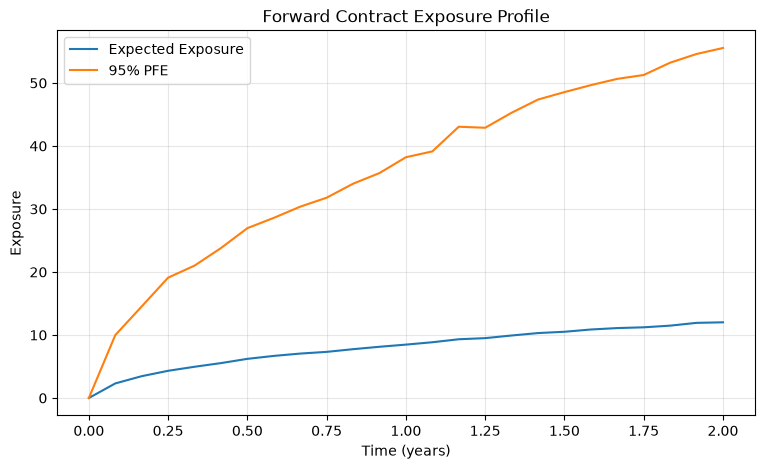

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(times, EE, label="Expected Exposure")
plt.plot(times, PFE_95, label="95% PFE")

plt.xlabel("Time (years)")
plt.ylabel("Exposure")
plt.title("Forward Contract Exposure Profile")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Comparison with the stylized PFE profiles

The simulated forward exposure profile increases with the time horizon.
As time passes, the distribution of the stock price becomes more
dispersed because there has been more time for market uncertainty to
accumulate. This produces a wider distribution of \(S(t)-K\), and in
particular a larger upper tail of positive exposures.

As expected, the 95% PFE is above EE because PFE measures a relatively
adverse point in the exposure distribution, whereas EE is an average.

The shape differs from the stylized interest-rate swap PFE shown in the
lecture. An IR swap typically has a hump-shaped exposure profile. Early
in the life of the swap, uncertainty increases as interest rates move,
which causes PFE to rise. Later, however, fewer cash flows remain and
the remaining maturity becomes shorter, reducing the amount of future
value that can be generated. As a result, the PFE eventually falls
towards zero as the swap approaches maturity.

The simplified forward used here does not have the same declining
remaining-cash-flow effect. Its MtM is defined directly as \(S(t)-K\),
so increasing uncertainty in the underlying produces a generally
increasing exposure profile over the simulated horizon.

### (b) Credit Valuation Adjustment

CVA represents the value of the expected loss associated with the
possibility that the counterparty defaults while the derivative has
positive exposure.

To estimate this loss, the exercise provides information about the
counterparty's credit risk through a CDS spread.

A Credit Default Swap (CDS) is a contract that provides protection
against the default of a reference entity. The CDS spread is the premium
paid for that protection. A higher CDS spread generally corresponds to
higher perceived default risk.

The CDS spread used here is 150 basis points:

$$
150\text{ bps}=1.50\%=0.015.
$$

The recovery rate is the fraction of the exposure that is assumed to be
recovered after a default.

With a recovery rate of 40%,

$$
R=0.40,
$$

the Loss Given Default is

$$
LGD=1-R=0.60.
$$

Therefore, if the counterparty defaults when the exposure is positive,
60% of that exposure is assumed to be lost.

The exercise also assumes a flat discount rate of 2%.

"Flat" means that the same interest rate is used for every maturity in
the two-year horizon. Using continuous compounding, the discount factor
at time \(t\) is

$$
B(t)=e^{-0.02t}.
$$

Future expected losses are multiplied by this discount factor because a
loss occurring in the future has a lower present value than an
equivalent loss occurring today.

For each future interval, three events determine the expected credit
loss:

1. the derivative must have positive exposure;
2. the counterparty must default during that interval;
3. only the fraction represented by LGD is lost.

The expected loss associated with interval \(i\) is therefore
approximated by

$$
LGD
\times
EE(t_i)
\times
q(t_{i-1},t_i).
$$

Since this possible loss occurs in the future, it is discounted back to
today using $$B(t_i)$$.

Summing across all future intervals gives

$$
CVA
\approx
LGD
\sum_i
B(t_i)
EE(t_i)
q(t_{i-1},t_i).
$$

Thus, CVA combines the size of the possible exposure, the probability of
default and the loss severity if default occurs.

### Default probabilities from the CDS spread

The CDS spread can be used to obtain a simple approximation of the
counterparty's default intensity, or hazard rate.

The exercise assumes a constant hazard rate

$$
\lambda
\approx
\frac{\text{CDS spread}}{LGD}.
$$

The intuition is that, in a simplified setting, the annual CDS premium
should approximately compensate for the expected annual credit loss:

$$
\text{CDS spread}
\approx
\lambda\times LGD.
$$

Therefore,

$$
\lambda
\approx
\frac{\text{spread}}{LGD}.
$$

Under a constant hazard rate, survival over an interval of length
$$\Delta t$$
 is approximated by

$$
e^{-\lambda\Delta t}.
$$

Because in terms of counting events, defaults occur as a Poisson process where $\lambda$ is the average arrival rate of defaults per unit of time.The probability of zero events (no defaults) occurring in a time interval of length $\Delta t$ for a Poisson process is given by the Poisson distribution formula:$$P(X = 0) = \frac{(\lambda \Delta t)^0 e^{-\lambda \Delta t}}{0!} = e^{-\lambda \Delta t}$$

Consequently, the default probability used for a monthly interval is

$$
q(t_{i-1},t_i)
\approx
1-e^{-\lambda\Delta t}.
$$

Since the simulation uses a monthly grid,

$$
\Delta t=\frac{1}{12}.
$$

Because both the CDS spread and recovery assumption are constant, the
same default probability is used for every monthly interval in this
simplified calculation.

In [36]:
# Credit parameters
cds_spread_bps = 150
cds_spread = cds_spread_bps / 10000

recovery = 0.40
LGD = 1 - recovery

discount_rate = 0.02

In [41]:
def calculate_cva(recovery, EE, times, cds_spread, discount_rate, dt):
    
    LGD = 1 - recovery
    
    # Constant hazard-rate approximation
    hazard_rate = cds_spread / LGD
    
    # Monthly default probability
    default_prob = 1 - np.exp(-hazard_rate * dt)
    
    # Discount factors
    discount_factors = np.exp(-discount_rate * times[1:])
    
    # CVA
    cva = LGD * np.sum(
        discount_factors
        * EE[1:]
        * default_prob
    )
    
    return {
        "Recovery": recovery,
        "LGD": LGD,
        "Hazard rate": hazard_rate,
        "Monthly default probability": default_prob,
        "CVA": cva
    }

In [42]:
result_40 = calculate_cva(
    recovery=0.40,
    EE=EE,
    times=times,
    cds_spread=cds_spread,
    discount_rate=discount_rate,
    dt=dt
)

result_20 = calculate_cva(
    recovery=0.20,
    EE=EE,
    times=times,
    cds_spread=cds_spread,
    discount_rate=discount_rate,
    dt=dt
)

In [43]:
cva_comparison = pd.DataFrame([
    result_40,
    result_20
])

cva_comparison

,Recovery,LGD,Hazard rate,Monthly default probability,CVA
0,0.4,0.6,0.02500,0.002081,0.242760
1,0.2,0.8,0.01875,0.001561,0.242823


In [44]:
cva_change = (
    result_20["CVA"] / result_40["CVA"] - 1
) * 100

print(f"Percentage change in CVA: {cva_change:.4f}%")

Percentage change in CVA: 0.0260%


### Conclusion

The exposure simulation shows that both EE and 95% PFE increase over
the two-year horizon. The dispersion of the simulated stock price grows
with time, which increases both the average positive exposure and the
upper tail of the exposure distribution.

This differs from the stylized IR-swap exposure profile discussed in
class. An IR swap typically has a hump-shaped PFE because increasing
market uncertainty is eventually offset by the declining number of
remaining cash flows as maturity approaches. The simplified forward
used in this exercise does not contain the same effect, so its exposure
profile continues to increase over the simulated horizon.

The CVA calculation combines expected exposure with the probability and
severity of counterparty default. Using the CDS spread, the hazard rate
is approximated as

$$
\lambda\approx\frac{\text{spread}}{LGD},
$$

and this is used to obtain monthly default probabilities.

Reducing recovery from 40% to 20% increases LGD from 60% to 80%.
However, because the CDS spread is held fixed, the implied hazard rate
falls at the same time. These two effects almost offset each other.

For small time intervals,

$$
q\approx\lambda\Delta t,
$$

so that

$$
LGD\times q
\approx
LGD
\frac{\text{spread}}{LGD}
\Delta t
=
\text{spread}\times\Delta t.
$$

Therefore, under the simplified constant-hazard approximation used in
this exercise, the resulting CVA is only weakly sensitive to the
recovery-rate assumption.